In [1]:
import sys; sys.path.append("..")
import pandas as pd, numpy as np
from src.features import extract_features, get_host

df = pd.read_csv("../data/PhiUSIIL_Phishing_URL_Dataset.csv", usecols=["URL", "label"])
df = df.drop_duplicates(subset="URL").copy()
df["phish"] = (df["label"] == 0).astype(int)   # 1 = phishing (positive class)
df["host"] = df["URL"].map(get_host)

feats = pd.DataFrame([extract_features(u) for u in df["URL"]], index=df.index)
data = pd.concat([df[["host", "phish"]], feats], axis=1)
print(data.shape)
print("Unique hosts:", data["host"].nunique())

(235370, 21)
Unique hosts: 219094


In [2]:
from sklearn.model_selection import GroupShuffleSplit

# Hosts that appear with both labels would confuse the model
conflict = data.groupby("host")["phish"].nunique()
conflict = conflict[conflict > 1].index
print("Hosts with both labels:", len(conflict))
data = data[~data["host"].isin(conflict)]

X = data.drop(columns=["host", "phish"])
y = data["phish"]
groups = data["host"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Phishing share train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))
print("Hosts shared between train and test:", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

Hosts with both labels: 58
Train: (188682, 19) Test: (46529, 19)
Phishing share train/test: 0.429 0.42
Hosts shared between train and test: 0


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

for name, m in {"Logistic Regression": LogisticRegression(max_iter=2000),
                "Random Forest": RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=42)}.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    print(name)
    print(classification_report(y_test, pred, target_names=["legitimate", "phishing"], digits=3))
    print(confusion_matrix(y_test, pred, labels=[1, 0]), "\n")

Logistic Regression
              precision    recall  f1-score   support

  legitimate      0.792     0.957     0.867     27010
    phishing      0.916     0.652     0.762     19519

    accuracy                          0.829     46529
   macro avg      0.854     0.804     0.814     46529
weighted avg      0.844     0.829     0.823     46529

[[12733  6786]
 [ 1174 25836]] 

Random Forest
              precision    recall  f1-score   support

  legitimate      0.798     0.952     0.868     27010
    phishing      0.909     0.667     0.770     19519

    accuracy                          0.832     46529
   macro avg      0.854     0.809     0.819     46529
weighted avg      0.845     0.832     0.827     46529

[[13027  6492]
 [ 1309 25701]] 



In [4]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix

m = HistGradientBoostingClassifier(random_state=42)
m.fit(X_train, y_train)
pred = m.predict(X_test)

print("Hist Gradient Boosting")
print(classification_report(y_test, pred, target_names=["legitimate", "phishing"], digits=3))
print(confusion_matrix(y_test, pred, labels=[1, 0]), "\n")

Hist Gradient Boosting
              precision    recall  f1-score   support

  legitimate      0.802     0.964     0.876     27010
    phishing      0.930     0.671     0.780     19519

    accuracy                          0.841     46529
   macro avg      0.866     0.818     0.828     46529
weighted avg      0.856     0.841     0.835     46529

[[13104  6415]
 [  979 26031]] 



In [5]:
p = m.predict_proba(X_test)[:, 1]          # probability of phishing (class 1)
is_ph = (y_test == 1).values

rows = []
for t in np.arange(0.05, 0.96, 0.05):
    flagged = p >= t
    fn = int((is_ph & ~flagged).sum())
    fp = int((~is_ph & flagged).sum())
    rows.append({"Threshold": round(t, 2),
                 "Phishing recall": round(1 - fn / is_ph.sum(), 3),
                 "Legit flagged %": round(fp / (~is_ph).sum() * 100, 1),
                 "FN": fn, "FP": fp})
pd.DataFrame(rows).set_index("Threshold")

,Phishing recall,Legit flagged %,FN,FP
Threshold,,,,
0.05,0.998,97.6,30,26367
0.10,0.988,88.0,232,23767
0.15,0.975,81.9,481,22115
0.20,0.820,29.4,3510,7949
0.25,0.775,17.2,4399,4657
0.30,0.742,11.5,5040,3095
0.35,0.721,8.2,5451,2219
0.40,0.697,6.2,5915,1664
0.45,0.683,4.6,6182,1242


In [6]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.ensemble import HistGradientBoostingClassifier

groups_train = groups.iloc[train_idx]
gb = HistGradientBoostingClassifier(random_state=42)
oof = cross_val_predict(gb, X_train, y_train, cv=GroupKFold(n_splits=5),
                        groups=groups_train, method="predict_proba")[:, 1]
is_ph_tr = (y_train == 1).values

rows = []
for t in [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]:
    fl = oof >= t
    rows.append({"Threshold": t,
                 "Phishing recall": round((fl & is_ph_tr).sum() / is_ph_tr.sum(), 3),
                 "Legit flagged %": round((fl & ~is_ph_tr).sum() / (~is_ph_tr).sum() * 100, 1)})
pd.DataFrame(rows).set_index("Threshold")

,Phishing recall,Legit flagged %
Threshold,,
0.20,0.828,29.8
0.25,0.764,17.3
0.30,0.730,11.3
0.35,0.709,7.8
0.40,0.695,6.1
0.45,0.683,4.7
0.50,0.667,3.6


In [7]:
import joblib, json, os
from sklearn.ensemble import HistGradientBoostingClassifier

os.makedirs("../models", exist_ok=True)
gb = HistGradientBoostingClassifier(random_state=42).fit(X_train, y_train)
joblib.dump(gb, "../models/url_model.joblib")

meta = {"features": list(X_train.columns), "low_max": 0.30, "high_min": 0.50}
with open("../models/url_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

p_te = gb.predict_proba(X_test)[:, 1]
print("Test recall at 0.5:", round(((p_te >= 0.5) & (y_test == 1)).sum() / (y_test == 1).sum(), 3))
print("Saved", len(meta["features"]), "features")

Test recall at 0.5: 0.671
Saved 19 features


In [8]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve

def reg_domain(host):
    p = host.split(".")
    if len(p) >= 3 and len(p[-1]) == 2 and p[-2] in {"co","com","org","net","ac","gov","edu","or","ne"}:
        return ".".join(p[-3:])
    return ".".join(p[-2:])

d = data.copy()
d["reg"] = d["host"].map(reg_domain)
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=7).split(d, d["phish"], d["reg"]))
print("Registered domains shared:", len(set(d["reg"].iloc[tr]) & set(d["reg"].iloc[te])))

ytr, yte = d["phish"].iloc[tr], d["phish"].iloc[te]
Xtr_n, Xte_n = d[X.columns].iloc[tr], d[X.columns].iloc[te]

tf = TfidfVectorizer(analyzer="char", ngram_range=(2, 4), min_df=5, sublinear_tf=True)
Xtr_t = tf.fit_transform(d["host"].iloc[tr])
Xte_t = tf.transform(d["host"].iloc[te])

gb2 = HistGradientBoostingClassifier(random_state=42).fit(Xtr_n, ytr)
lr2 = LogisticRegression(max_iter=1000).fit(Xtr_t, ytr)

p_gb = gb2.predict_proba(Xte_n)[:, 1]
p_lr = lr2.predict_proba(Xte_t)[:, 1]
p_avg = (p_gb + p_lr) / 2

def report(name, p):
    fpr, tpr, _ = roc_curve(yte, p)
    print(f"{name:28s} AUC={roc_auc_score(yte, p):.3f}  "
          f"recall at 5% legit flagged={tpr[fpr <= 0.05].max():.3f}  "
          f"at 10%={tpr[fpr <= 0.10].max():.3f}")

report("Current features (GB)", p_gb)
report("Character n-grams (LR)", p_lr)
report("Average of both", p_avg)

Registered domains shared: 0
Current features (GB)        AUC=0.847  recall at 5% legit flagged=0.613  at 10%=0.654
Character n-grams (LR)       AUC=0.911  recall at 5% legit flagged=0.721  at 10%=0.781
Average of both              AUC=0.911  recall at 5% legit flagged=0.736  at 10%=0.790


In [9]:
for seed in [42, 7, 123]:
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
                  .split(d, d["phish"], d["reg"]))
    ytr, yte = d["phish"].iloc[tr], d["phish"].iloc[te]

    tf_s = TfidfVectorizer(analyzer="char", ngram_range=(2, 4), min_df=5, sublinear_tf=True)
    Xtr_t = tf_s.fit_transform(d["host"].iloc[tr])
    Xte_t = tf_s.transform(d["host"].iloc[te])

    gb_s = HistGradientBoostingClassifier(random_state=42).fit(d[X.columns].iloc[tr], ytr)
    lr_s = LogisticRegression(max_iter=1000).fit(Xtr_t, ytr)

    for name, p in [("Current features (GB)", gb_s.predict_proba(d[X.columns].iloc[te])[:, 1]),
                    ("Character n-grams (LR)", lr_s.predict_proba(Xte_t)[:, 1])]:
        fpr, tpr, _ = roc_curve(yte, p)
        print(f"seed {seed:3d} | {name:24s} AUC={roc_auc_score(yte, p):.3f}  "
              f"recall at 5%={tpr[fpr <= 0.05].max():.3f}")

seed  42 | Current features (GB)    AUC=0.826  recall at 5%=0.538
seed  42 | Character n-grams (LR)   AUC=0.898  recall at 5%=0.686
seed   7 | Current features (GB)    AUC=0.847  recall at 5%=0.613
seed   7 | Character n-grams (LR)   AUC=0.911  recall at 5%=0.721
seed 123 | Current features (GB)    AUC=0.831  recall at 5%=0.605
seed 123 | Character n-grams (LR)   AUC=0.885  recall at 5%=0.646


In [10]:
names = np.array(tf.get_feature_names_out())
w = lr2.coef_[0]
print("Most phishing-like:", names[np.argsort(w)[-25:]][::-1].tolist())
print("Most legitimate-like:", names[np.argsort(w)[:25]].tolist())

Most phishing-like: ['.cf', '.w', '.ga', '.ml', '.g', '.top', '1.', '.we', 'cf', '.t', '.x', '.to', '.jp.', 'jp.', '.rep', '.gq', '3.', 'epl.', 'gq', 'dns', '.web', '.m', '.sit', '.s', 'mail']
Most legitimate-like: ['.gov', '.go', '.jp', '.edu', '.ed', '.it', '.de', '.gr', '.com', '.ie', '.se', '.or', 'gov', '.be', '.org', '.ca', '.sk', '.nl', '.cz', '.uk', '.mil', '.pt', 'com', '.ac.', '.tv']


In [11]:
d["tld"] = d["host"].str.split(".").str[-1]
d["host_noTLD"] = d["host"].str.rsplit(".", n=1).str[0]

def fit_eval(col, label):
    tfx = TfidfVectorizer(analyzer="char", ngram_range=(2, 4), min_df=5, sublinear_tf=True)
    A = tfx.fit_transform(d[col].iloc[tr]); B = tfx.transform(d[col].iloc[te])
    m_ = LogisticRegression(max_iter=1000).fit(A, ytr)
    p_ = m_.predict_proba(B)[:, 1]
    fpr, tpr, _ = roc_curve(yte, p_)
    print(f"{label:28s} AUC={roc_auc_score(yte, p_):.3f}  recall at 5%={tpr[fpr <= 0.05].max():.3f}")

fit_eval("tld", "TLD only")
fit_eval("host_noTLD", "Host without TLD")
fit_eval("host", "Full host (reference)")

TLD only                     AUC=0.773  recall at 5%=0.422
Host without TLD             AUC=0.845  recall at 5%=0.584
Full host (reference)        AUC=0.885  recall at 5%=0.646


In [12]:
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline

# Use the seed-42 split so results are reproducible
tr42, te42 = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
                  .split(d, d["phish"], d["reg"]))
host_tr, y_tr = d["host"].iloc[tr42], d["phish"].iloc[tr42]
host_te, y_te = d["host"].iloc[te42], d["phish"].iloc[te42]
grp_tr = d["reg"].iloc[tr42]

pipe = make_pipeline(
    TfidfVectorizer(analyzer="char", ngram_range=(2, 4), min_df=5, sublinear_tf=True),
    LogisticRegression(max_iter=1000),
)

# Out-of-fold probabilities on the training set only
oof = np.zeros(len(host_tr))
for a, b in GroupKFold(n_splits=5).split(host_tr, y_tr, grp_tr):
    pipe.fit(host_tr.iloc[a], y_tr.iloc[a])
    oof[b] = pipe.predict_proba(host_tr.iloc[b])[:, 1]

is_ph = (y_tr == 1).values
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    fl = oof >= t
    rows.append({"Threshold": t,
                 "Phishing recall": round((fl & is_ph).sum() / is_ph.sum(), 3),
                 "Legit flagged %": round((fl & ~is_ph).sum() / (~is_ph).sum() * 100, 1)})
pd.DataFrame(rows).set_index("Threshold")

,Phishing recall,Legit flagged %
Threshold,,
0.2,0.908,35.2
0.3,0.844,16.9
0.4,0.785,8.3
0.5,0.727,4.1
0.6,0.664,2.0
0.7,0.583,0.9


In [13]:
import joblib, json

final_pipe = make_pipeline(
    TfidfVectorizer(analyzer="char", ngram_range=(2, 4), min_df=5, sublinear_tf=True),
    LogisticRegression(max_iter=1000),
).fit(host_tr, y_tr)

p_te = final_pipe.predict_proba(host_te)[:, 1]
is_te = (y_te == 1).values
for t in [0.3, 0.5]:
    fl = p_te >= t
    print(f"Test, threshold {t}: recall={(fl & is_te).sum() / is_te.sum():.3f}, "
          f"legit flagged={(fl & ~is_te).sum() / (~is_te).sum() * 100:.1f}%")

joblib.dump(final_pipe, "../models/ngram_model.joblib")
with open("../models/ngram_meta.json", "w") as f:
    json.dump({"low_max": 0.30, "high_min": 0.50}, f, indent=2)
print("Saved")

Test, threshold 0.3: recall=0.798, legit flagged=16.7%
Test, threshold 0.5: recall=0.676, legit flagged=4.4%
Saved


In [14]:
rl = pd.read_csv("../data/real_links.csv")
rl["host"] = rl["url"].map(get_host)
rl["p"] = final_pipe.predict_proba(rl["host"])[:, 1]
rl["band"] = pd.cut(rl["p"], [0, .3, .5, 1.01], labels=["Low", "Medium", "High"], right=False)

print(pd.crosstab(rl["label"].map({0: "legitimate", 1: "phishing"}), rl["band"]))
print(rl.sort_values("p", ascending=False)[["host", "label", "p", "band"]].round(3).to_string())

band        Low  Medium  High
label                        
legitimate   16       9    18
phishing      1       9    49
                                                               host  label      p    band
43                                   paypal-secure-login-verify.top      1  0.999    High
47                           netflix-billing-update.firebaseapp.com      1  0.999    High
46                     microsoft-support-alert-48213.weeblysite.com      1  0.999    High
44                                        amaz0n-account-update.xyz      1  0.999    High
50                                       login-update-dhl-parcel.ml      1  0.999    High
48                                         appleid-locked-verify.ga      1  0.992    High
82                                                  163.123.183.104      1  0.991    High
49                                       commbank-netbank-secure.cf      1  0.987    High
33                                             m365.cloud.microsoft   

In [15]:
rl = pd.read_csv("../data/real_links.csv")
rl["url"] = rl["url"].str.replace(r"\.\.\.$", "", regex=True)
rl["url"] = rl["url"].str.replace(r"\?.*$", "", regex=True)   # drops query strings (emails, tracking IDs)
rl["host"] = rl["url"].map(get_host).str.rstrip(".")

rl["source"] = np.where(rl["label"] == 0, "legit_manual",
                np.where(rl.groupby("label").cumcount() < 20, "synthetic", "phishtank"))
rl.loc[rl["host"] == "googleadservices.com", "source"] = "redirect_abuse"

before = len(rl)
rl = rl.drop_duplicates(subset="host").reset_index(drop=True)
print("Rows:", before, "->", len(rl), "after removing duplicate hosts")

main = rl[rl["source"] != "redirect_abuse"].copy()
main["p"] = final_pipe.predict_proba(main["host"])[:, 1]
main["band"] = pd.cut(main["p"], [0, .3, .5, 1.01], labels=["Low", "Medium", "High"], right=False)

print(pd.crosstab(main["source"], main["band"]))
print(main.groupby("source")["p"].apply(lambda s: (s >= .3).mean()).round(2).rename("share flagged Medium or High"))
main.to_csv("../reports/real_link_results.csv", index=False)


Rows: 102 -> 95 after removing duplicate hosts
band          Low  Medium  High
source                         
legit_manual   16       7    17
phishtank       1       5    28
synthetic       0       2    18
source
legit_manual    0.60
phishtank       0.97
synthetic       1.00
Name: share flagged Medium or High, dtype: float64


In [16]:
tr_df = pd.read_csv("../data/top-1m.csv", header=None, names=["rank", "domain"])
tr_df["domain"] = tr_df["domain"].str.lower()

# 1. Skip infrastructure and ambiguous hosting platforms
bad = ("amazonaws", "akamai", "akadns", "cloudfront", "fbcdn", "gstatic", "googleapis",
       "googleusercontent", "cdn", "gtld-servers", "azure", "windows.net", "trafficmanager",
       "github.io", "pages.dev", "netlify", "weebly", "wixsite", "blogspot", "firebaseapp",
       "web.app", "herokuapp", "000webhost", "glitch.me", "workers.dev", "vercel.app",
       "dns", "ns1", "ntp", "arpa", "root-servers")
tr_df = tr_df[~tr_df["domain"].str.contains("|".join(bad), regex=True)]

# 2. Use ranks 200 to 60,000 (skips the infrastructure-heavy top, keeps real sites)
tr_df = tr_df[(tr_df["rank"] >= 200) & (tr_df["rank"] <= 60000)]

# 3. Remove anything in your independent real-link test set
rl_hosts = set(pd.read_csv("../data/real_links.csv")["url"].map(get_host))
tr_df = tr_df[~tr_df["domain"].isin(rl_hosts)]

# 4. Sample 40,000 hosts as extra legitimate examples
extra = tr_df.sample(min(40000, len(tr_df)), random_state=42).copy()
extra["host"] = extra["domain"].map(get_host)
extra["phish"] = 0
print("Tranco hosts added:", len(extra))

# 5. Combine with the original training data (host + label only)
base = data[["host", "phish"]].copy()
comb = pd.concat([base, extra[["host", "phish"]]], ignore_index=True)
comb = comb.drop_duplicates(subset="host")
conflict = comb.groupby("host")["phish"].nunique()
comb = comb[~comb["host"].isin(conflict[conflict > 1].index)].reset_index(drop=True)
comb["reg"] = comb["host"].map(reg_domain)
print("Combined:", comb.shape, "| phishing share:", round(comb["phish"].mean(), 3))

Tranco hosts added: 40000
Combined: (253779, 3) | phishing share: 0.332


In [17]:
from sklearn.pipeline import make_pipeline

tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
                  .split(comb, comb["phish"], comb["reg"]))
print("Registered domains shared:", len(set(comb["reg"].iloc[tr_i]) & set(comb["reg"].iloc[te_i])))

pipe2 = make_pipeline(
    TfidfVectorizer(analyzer="char", ngram_range=(2, 4), min_df=5, sublinear_tf=True),
    LogisticRegression(max_iter=1000, class_weight="balanced"),
).fit(comb["host"].iloc[tr_i], comb["phish"].iloc[tr_i])

p_hold = pipe2.predict_proba(comb["host"].iloc[te_i])[:, 1]
y_hold = comb["phish"].iloc[te_i]
fpr, tpr, _ = roc_curve(y_hold, p_hold)
print(f"Held-out AUC={roc_auc_score(y_hold, p_hold):.3f}  "
      f"recall at 5% legit flagged={tpr[fpr <= .05].max():.3f}  at 10%={tpr[fpr <= .10].max():.3f}")

# Independent real-link check (same cleaning as before)
chk = main.copy()
chk["p2"] = pipe2.predict_proba(chk["host"])[:, 1]
chk["band2"] = pd.cut(chk["p2"], [0, .3, .5, 1.01], labels=["Low", "Medium", "High"], right=False)
print(pd.crosstab(chk["source"], chk["band2"]))
print(chk.groupby("source")["p2"].apply(lambda s: (s >= .3).mean()).round(2).rename("share flagged Medium or High"))


Registered domains shared: 0
Held-out AUC=0.877  recall at 5% legit flagged=0.617  at 10%=0.700
band2         Low  Medium  High
source                         
legit_manual   19      11    10
phishtank       0       4    30
synthetic       0       1    19
source
legit_manual    0.52
phishtank       1.00
synthetic       1.00
Name: share flagged Medium or High, dtype: float64


## Real-link check and Tranco experiment

### 1. Real-link test set
A separate file, `data/real_links.csv`, was built to test the model on links from outside the training data. It was **not used for training or threshold selection**.

| Group | Source | n (94) |
|---|---|---|
| legit_manual | Well-known sites I chose, plus links from a genuine email | 40 |
| phishtank | Host names copied from PhishTank on [date copied] | 34 |
| synthetic | Phishing-style hosts written by Claude, not real reports | 20 |

Cleaning: trailing `...` (PhishTank truncates long URLs) and query strings were removed, duplicate hosts were dropped (102 rows to 95), and one Google ad-redirect row was excluded because its host is genuinely Google's. No reported phishing site was visited.

### 2. Result: model trained on the PhiUSIIL data only
| Group | Low | Medium | High | Flagged Medium or High |
|---|---|---|---|---|
| legit_manual | 16 | 7 | 17 | 60% |
| phishtank | 1 | 5 | 28 | 97% |
| synthetic | 0 | 2 | 18 | 100% |

- On held-out data from the same dataset, about 4% of legitimate hosts reached the High band. On well-known real sites, **17 of 40 (42.5%) reached High**. The test-set false-alarm rate does not carry over.
- Likely cause: the dataset's legitimate class is mostly government, education and non-profit sites, so brand names, big-tech subdomains and newer TLDs look unusual to the model. This is dataset bias.
- The PhishTank result (33 of 34 flagged) is not strong evidence of real-world detection. The sample is dominated by a few campaigns using obvious markers (`.cfd`, `.sbs`, `.shop`, free hosting), and has almost no phishing on clean `.com` domains.
- The synthetic group only shows the model recognises obvious markers and is not a detection rate.

### 3. Experiment: adding popular domains from Tranco
40,000 hosts from the Tranco list (ranks 200 to 60,000, downloaded [05/11/2026]) were added as legitimate examples. Infrastructure and shared-hosting domains were removed, and any host in `real_links.csv` was excluded so the test stayed independent. The model was retrained with the same split by registered domain (shared domains: 0).

| Group | High before | High after | Medium or High before | Medium or High after |
|---|---|---|---|---|
| legit_manual (40) | 17 | 10 | 60% | 52% |
| phishtank (34) | 28 | 30 | 97% | 100% |
| synthetic (20) | 18 | 19 | 100% | 100% |

- High-band false alarms fell from 42% to 25%, but Medium or High barely moved (60% to 52%).
- Held-out AUC was 0.877. It is **not comparable** with earlier figures, because the legitimate class and class balance changed.
- The thresholds (0.30 and 0.50) were chosen for the old data and `class_weight="balanced"` was used, so the bands are probably miscalibrated. They have not been re-picked.

### 4. Limitations
- Only 40 legitimate and 34 PhishTank links, so each link moves a rate by about 2.5 to 3 points.
- The PhishTank links come from a small number of campaigns, with few clean-domain phishing hosts.
- A host-name-only model cannot see the page, the certificate, the domain age or the path, so phishing on a clean `.com` is largely undetectable by name.
- The thresholds were not re-selected after adding Tranco data.

### 5. Next steps
1. Re-pick thresholds by grouped cross-validation on the combined data.
2. Add a known-domain allowlist as a separate layer, and state that it does not catch hijacked popular sites.
3. Report the progression: baseline, n-grams, Tranco, allowlist.

In [18]:
from sklearn.model_selection import GroupKFold
from sklearn.base import clone

host_tr2 = comb["host"].iloc[tr_i].reset_index(drop=True)
y_tr2 = comb["phish"].iloc[tr_i].reset_index(drop=True)
grp_tr2 = comb["reg"].iloc[tr_i].reset_index(drop=True)

# 1. Out-of-fold probabilities on the training set only
oof2 = np.zeros(len(host_tr2))
for a, b in GroupKFold(n_splits=5).split(host_tr2, y_tr2, grp_tr2):
    m_ = clone(pipe2).fit(host_tr2.iloc[a], y_tr2.iloc[a])
    oof2[b] = m_.predict_proba(host_tr2.iloc[b])[:, 1]

is_ph2 = (y_tr2 == 1).values
legit_p = oof2[~is_ph2]

# 2. Thresholds from the legitimate-host score distribution
HIGH_T = float(np.quantile(legit_p, 0.95))   # 5% of legitimate flagged
MED_T = float(np.quantile(legit_p, 0.85))    # 15% of legitimate flagged
print(f"Medium edge = {MED_T:.3f}, High edge = {HIGH_T:.3f}")

for name, t in [("Medium edge", MED_T), ("High edge", HIGH_T)]:
    fl = oof2 >= t
    print(f"Training CV, {name} {t:.3f}: phishing recall={(fl & is_ph2).sum() / is_ph2.sum():.3f}, "
          f"legit flagged={(fl & ~is_ph2).sum() / (~is_ph2).sum() * 100:.1f}%")

# 3. One evaluation on the held-out test set (report it, do not tune on it)
p_h = pipe2.predict_proba(comb["host"].iloc[te_i])[:, 1]
y_h = (comb["phish"].iloc[te_i] == 1).values
for name, t in [("Medium edge", MED_T), ("High edge", HIGH_T)]:
    fl = p_h >= t
    print(f"Held-out test, {name}: recall={(fl & y_h).sum() / y_h.sum():.3f}, "
          f"legit flagged={(fl & ~y_h).sum() / (~y_h).sum() * 100:.1f}%")

# 4. Real-link check (reporting only, not used to choose anything)
chk = main.copy()
chk["p2"] = pipe2.predict_proba(chk["host"])[:, 1]
chk["band3"] = pd.cut(chk["p2"], [0, MED_T, HIGH_T, 1.01], labels=["Low", "Medium", "High"], right=False)
print(pd.crosstab(chk["source"], chk["band3"]))
print(chk.groupby("source")["p2"].apply(lambda s: (s >= MED_T).mean()).round(2)
      .rename("share flagged Medium or High"))

Medium edge = 0.391, High edge = 0.546
Training CV, Medium edge 0.391: phishing recall=0.805, legit flagged=15.0%
Training CV, High edge 0.546: phishing recall=0.705, legit flagged=5.0%
Held-out test, Medium edge: recall=0.750, legit flagged=14.8%
Held-out test, High edge: recall=0.623, legit flagged=5.2%
band3         Low  Medium  High
source                         
legit_manual   27       4     9
phishtank       2       3    29
synthetic       1       0    19
source
legit_manual    0.32
phishtank       0.94
synthetic       0.95
Name: share flagged Medium or High, dtype: float64


In [19]:
import joblib, json

joblib.dump(pipe2, "../models/ngram_tranco_model.joblib")

pop = pd.read_csv("../data/top-1m.csv", header=None, names=["rank", "domain"])
pop = pop[pop["rank"] <= 5000]["domain"].str.lower()
allow = sorted({reg_domain(d) for d in pop})

with open("../models/ngram_tranco_meta.json", "w") as f:
    json.dump({"low_max": MED_T, "high_min": HIGH_T, "allowlist": allow}, f)
print("Saved. Allowlist size:", len(allow))

Saved. Allowlist size: 4994


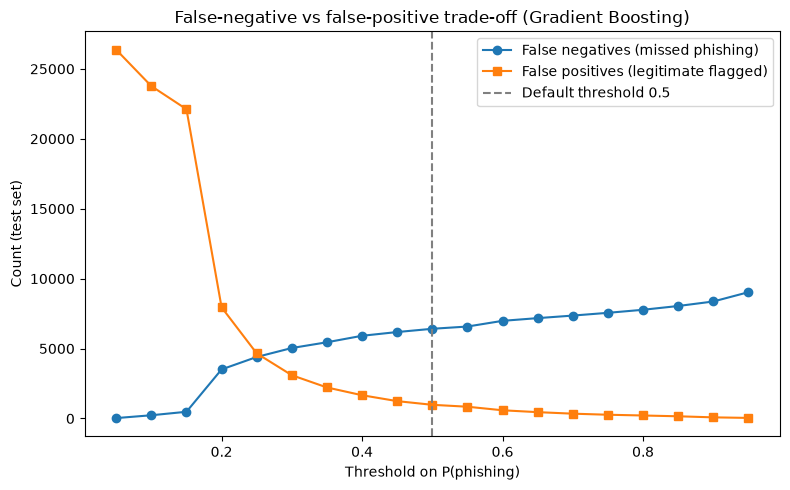

In [20]:
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier

gbm = HistGradientBoostingClassifier(random_state=42).fit(X_train, y_train)
p = gbm.predict_proba(X_test)[:, 1]            # probability of phishing (class 1)
is_ph = (y_test == 1).values

ts = np.arange(0.05, 0.96, 0.05)
fn = [int((is_ph & ~(p >= t)).sum()) for t in ts]    # missed phishing
fp = [int((~is_ph & (p >= t)).sum()) for t in ts]    # legitimate flagged

plt.figure(figsize=(8, 5))
plt.plot(ts, fn, marker="o", label="False negatives (missed phishing)")
plt.plot(ts, fp, marker="s", label="False positives (legitimate flagged)")
plt.axvline(0.5, color="grey", linestyle="--", label="Default threshold 0.5")
plt.xlabel("Threshold on P(phishing)")
plt.ylabel("Count (test set)")
plt.title("False-negative vs false-positive trade-off (Gradient Boosting)")
plt.legend()
plt.tight_layout()
plt.savefig("../reports/fig1_threshold_tradeoff.png", dpi=150)
plt.show()

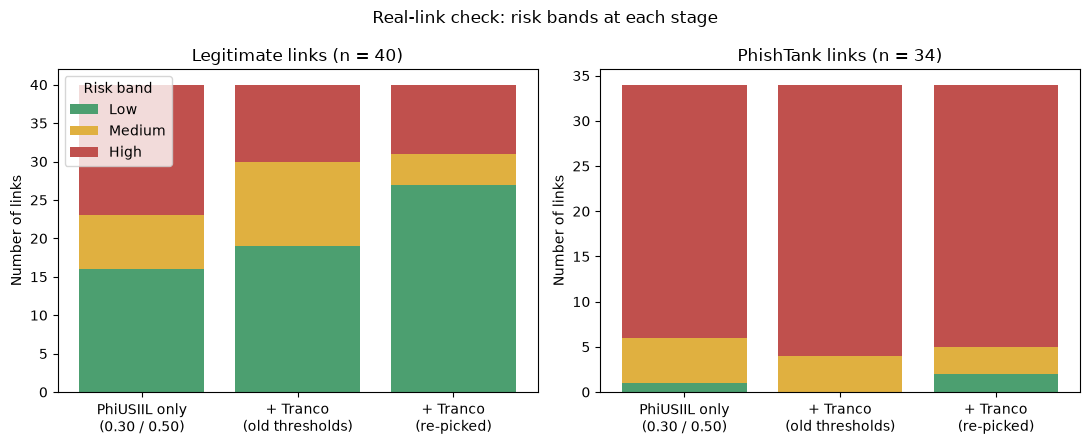

In [21]:
import numpy as np
import matplotlib.pyplot as plt

stages = ["PhiUSIIL only\n(0.30 / 0.50)", "+ Tranco\n(old thresholds)", "+ Tranco\n(re-picked)"]
data = {
    "Legitimate links (n = 40)": [(16, 7, 17), (19, 11, 10), (27, 4, 9)],
    "PhishTank links (n = 34)":  [(1, 5, 28),  (0, 4, 30),   (2, 3, 29)],
}
colors = ["#4c9f70", "#e0b040", "#c0504d"]
labels = ["Low", "Medium", "High"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=False)
for ax, (title, rows) in zip(axes, data.items()):
    arr = np.array(rows)
    bottom = np.zeros(len(stages))
    for i, (lab, col) in enumerate(zip(labels, colors)):
        ax.bar(stages, arr[:, i], bottom=bottom, label=lab, color=col)
        bottom += arr[:, i]
    ax.set_title(title)
    ax.set_ylabel("Number of links")
axes[0].legend(title="Risk band")
plt.suptitle("Real-link check: risk bands at each stage")
plt.tight_layout()
plt.savefig("../reports/fig2_real_link_bands.png", dpi=150)
plt.show()